In [ ]:
# ================================================
# CELL 1: Install dependencies
# After this → Runtime > Restart Runtime
# ================================================
!pip install hy3dgen trimesh scikit-image pyrender -q
!pip install "numpy>=1.26.0,<2.0.0" -q --force-reinstall
!pip install transformers timm huggingface_hub -q   # added huggingface_hub
!pip uninstall -y flax jax jaxlib -q 2>/dev/null

print("✅ Done — Restart runtime now, then run Cell 2")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 40.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.5/115.5 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 741.0/741.0 kB 34.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 44.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 41.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 60.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.7/180.7 kB 19.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 66.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 314.2/314.2 kB 21.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 106.5/106.5 MB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 261.0/261.0 kB 12.4 MB/s eta 0:00:00
   ━━━━━

In [ ]:
# ================================================
# CELL 2: Verify
# ================================================
import torch
import numpy as np
import trimesh
from PIL import Image
import transformers

print(f"PyTorch:        {torch.__version__}")
print(f"CUDA:           {torch.cuda.is_available()}")
print(f"GPU:            {torch.cuda.get_device_name(0)}")
print(f"Transformers:   {transformers.__version__}")
print(f"NumPy:          {np.__version__}")
print(f"Trimesh:        {trimesh.__version__}")
print("\n✅ All good — continue to Cell 3")

PyTorch:        2.10.0+cu128
CUDA:           True
GPU:            Tesla T4
Transformers:   5.0.0
NumPy:          1.26.4
Trimesh:        4.12.2

✅ All good — continue to Cell 3


In [ ]:
# ================================================
# CELL 3: Load Depth Anything V2 (small model)
# ================================================
from transformers import pipeline as hf_pipeline

print("Loading Depth Anything V2...")
depth_estimator = hf_pipeline(
    task="depth-estimation",
    model="depth-anything/Depth-Anything-V2-Small-hf",
    device=0,
)
print("✅ Depth Anything V2 ready!")
print(f"VRAM used: {torch.cuda.memory_allocated()/1e9:.2f} GB")
print(f"VRAM free: {torch.cuda.mem_get_info()[0]/1e9:.2f} GB")

Loading Depth Anything V2...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/99.2M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

The image processor of type `DPTImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


✅ Depth Anything V2 ready!
VRAM used: 0.10 GB
VRAM free: 15.41 GB


📤 Upload your image:


Saving Screenshot 2026-05-07 091803.png to Screenshot 2026-05-07 091803.png
   Original size: (525, 351)
   Object bounds: x=0-524, y=7-350
   Saved: preprocessed_depth_guided.png and depth_map.png


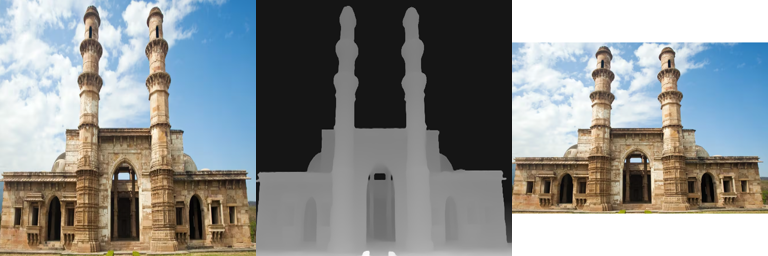

Left: Original | Middle: Depth | Right: Preprocessed


In [ ]:
# ================================================
# CELL 4: Upload image + depth-guided preprocessing
# ================================================
from google.colab import files
from PIL import Image
import numpy as np
import os

print("📤 Upload your image:")
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

def depth_guided_preprocess(path, output_size=512):
    img = Image.open(path).convert("RGB")
    print(f"   Original size: {img.size}")

    depth_result = depth_estimator(img)
    depth_map = np.array(depth_result["depth"])
    d_min, d_max = depth_map.min(), depth_map.max()
    depth_norm = (depth_map - d_min) / (d_max - d_min + 1e-8)

    threshold = np.percentile(depth_norm, 40)
    obj_mask = depth_norm > threshold
    rows = np.any(obj_mask, axis=1)
    cols = np.any(obj_mask, axis=0)
    rmin, rmax = np.where(rows)[0][[0, -1]]
    cmin, cmax = np.where(cols)[0][[0, -1]]
    print(f"   Object bounds: x={cmin}-{cmax}, y={rmin}-{rmax}")

    obj_h = rmax - rmin
    obj_w = cmax - cmin
    margin_y = int(obj_h * 0.12)
    margin_x = int(obj_w * 0.12)
    rmin = max(0, rmin - margin_y)
    rmax = min(depth_map.shape[0], rmax + margin_y)
    cmin = max(0, cmin - margin_x)
    cmax = min(depth_map.shape[1], cmax + margin_x)

    cropped = img.crop((cmin, rmin, cmax, rmax))
    cw, ch = cropped.size
    max_dim = max(cw, ch)
    canvas = Image.new("RGB", (max_dim, max_dim), (255, 255, 255))
    canvas.paste(cropped, ((max_dim - cw)//2, (max_dim - ch)//2))
    final = canvas.resize((output_size, output_size), Image.LANCZOS)

    out_path = "preprocessed_depth_guided.png"
    depth_path = "depth_map.png"
    final.save(out_path)
    depth_vis = Image.fromarray((depth_norm * 255).astype(np.uint8))
    depth_vis.save(depth_path)

    print(f"   Saved: {out_path} and {depth_path}")
    return out_path, depth_path, depth_norm

processed_path, depth_path, _ = depth_guided_preprocess(img_path)

from IPython.display import display
orig = Image.open(img_path).resize((256, 256))
depth = Image.open(depth_path).resize((256, 256))
proc = Image.open(processed_path).resize((256, 256))
comparison = Image.new("RGB", (256*3, 256))
comparison.paste(orig, (0,0))
comparison.paste(depth, (256,0))
comparison.paste(proc, (512,0))
display(comparison)
print("Left: Original | Middle: Depth | Right: Preprocessed")

In [ ]:
# ================================================
# CELL 5: Load Hunyuan3D-2 with dynamic snapshot
# ================================================
import torch, gc, os, sys
from pathlib import Path

del depth_estimator
gc.collect()
torch.cuda.empty_cache()
print(f"VRAM freed: {torch.cuda.mem_get_info()[0]/1e9:.2f} GB available")

for mod in list(sys.modules.keys()):
    if 'hy3dgen' in mod:
        del sys.modules[mod]

from hy3dgen.shapegen import Hunyuan3DDiTFlowMatchingPipeline

cache_dir = Path("/root/.cache/huggingface/hub")
snapshots = list(cache_dir.glob("models--tencent--Hunyuan3D-2/snapshots/*"))

if not snapshots:
    print("Downloading Hunyuan3D-2 weights (~5GB) ...")
    _tmp = Hunyuan3DDiTFlowMatchingPipeline.from_pretrained('tencent/Hunyuan3D-2')
    del _tmp
    gc.collect()
    torch.cuda.empty_cache()
    snapshots = list(cache_dir.glob("models--tencent--Hunyuan3D-2/snapshots/*"))

SNAPSHOT = str(snapshots[0])   # This variable will be used later for texture
BASE = f"{SNAPSHOT}/hunyuan3d-dit-v2-0"
CKPT = f"{BASE}/model.fp16.safetensors"
CONFIG = f"{BASE}/config.yaml"

print(f"Loading shape pipeline from: {CKPT}")
pipeline = Hunyuan3DDiTFlowMatchingPipeline.from_single_file(
    CKPT, CONFIG, device='cuda', dtype=torch.float16, use_safetensors=True
)

print(f"Pipeline loaded. VRAM used: {torch.cuda.memory_allocated()/1e9:.2f} GB")
print(f"VRAM free: {torch.cuda.mem_get_info()[0]/1e9:.2f} GB")

VRAM freed: 15.47 GB available


2026-05-07 03:51:17,471 - hy3dgen.shapgen - INFO - Try to load model from local path: /root/.cache/hy3dgen/tencent/Hunyuan3D-2/hunyuan3d-dit-v2-0
INFO:hy3dgen.shapgen:Try to load model from local path: /root/.cache/hy3dgen/tencent/Hunyuan3D-2/hunyuan3d-dit-v2-0
2026-05-07 03:51:17,474 - hy3dgen.shapgen - INFO - Model path not exists, try to download from huggingface
INFO:hy3dgen.shapgen:Model path not exists, try to download from huggingface


Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

2026-05-07 03:55:47,901 - hy3dgen.shapgen - INFO - Loading model from /root/.cache/huggingface/hub/models--tencent--Hunyuan3D-2/snapshots/9cd649ba6913f7a852e3286bad86bfa9a2d83dcf/hunyuan3d-dit-v2-0/model.fp16.safetensors
INFO:hy3dgen.shapgen:Loading model from /root/.cache/huggingface/hub/models--tencent--Hunyuan3D-2/snapshots/9cd649ba6913f7a852e3286bad86bfa9a2d83dcf/hunyuan3d-dit-v2-0/model.fp16.safetensors
2026-05-07 03:56:42,499 - hy3dgen.shapgen - INFO - Loading model from /root/.cache/huggingface/hub/models--tencent--Hunyuan3D-2/snapshots/9cd649ba6913f7a852e3286bad86bfa9a2d83dcf/hunyuan3d-dit-v2-0/model.fp16.safetensors
INFO:hy3dgen.shapgen:Loading model from /root/.cache/huggingface/hub/models--tencent--Hunyuan3D-2/snapshots/9cd649ba6913f7a852e3286bad86bfa9a2d83dcf/hunyuan3d-dit-v2-0/model.fp16.safetensors


Loading shape pipeline from: /root/.cache/huggingface/hub/models--tencent--Hunyuan3D-2/snapshots/9cd649ba6913f7a852e3286bad86bfa9a2d83dcf/hunyuan3d-dit-v2-0/model.fp16.safetensors
Pipeline loaded. VRAM used: 4.94 GB
VRAM free: 10.46 GB


In [ ]:
# ================================================
# CELL 6: Generate 1 mesh
# ================================================
SEEDS = [42]
print(f"Generating mesh (seed={SEEDS[0]})... ~10 min")

raw_candidates = []
for seed in SEEDS:
    try:
        mesh = pipeline(
            image=processed_path,
            num_inference_steps=50,
            guidance_scale=7.5,
            octree_resolution=384,
            generator=torch.Generator(device="cuda").manual_seed(seed),
        )[0]
        raw_candidates.append((seed, mesh))
        print(f"✅ Mesh generated: faces={len(mesh.faces):,}")
    except RuntimeError as e:
        if "out of memory" in str(e).lower():
            print("⚠️ OOM, retrying with octree_resolution=256...")
            torch.cuda.empty_cache()
            mesh = pipeline(
                image=processed_path,
                num_inference_steps=50,
                guidance_scale=7.5,
                octree_resolution=256,
                generator=torch.Generator(device="cuda").manual_seed(seed),
            )[0]
            raw_candidates.append((seed, mesh))
            print(f"✅ Fallback OK: faces={len(mesh.faces):,}")
        else:
            raise

best_seed, best_mesh = raw_candidates[0]
print(f"\n✅ Generation complete. Best seed: {best_seed}")

Generating mesh (seed=42)... ~10 min


Volume Decoding: 100%|██████████| 7134/7134 [02:23<00:00, 49.82it/s]


✅ Mesh generated: faces=1,419,800

✅ Generation complete. Best seed: 42


In [ ]:
# ================================================
# CELL 7: Score mesh (render fallback works)
# ignore the cell
# ================================================
import trimesh
import numpy as np
from PIL import Image
from skimage.metrics import structural_similarity as ssim
import pyrender

def render_mesh_snapshot(mesh, image_size=256):
    try:
        scene = mesh.scene()
        if not scene.camera:
            from trimesh.scene import cameras
            scene.camera = cameras.Camera(fov=(60, 60))
        r = pyrender.OffscreenRenderer(image_size, image_size)
        pyrender_scene = pyrender.Scene.from_trimesh_scene(scene)
        color, _ = r.render(pyrender_scene)
        r.delete()
        return Image.fromarray(color)
    except Exception as e:
        print(f"   Render failed: {e}")
        return None

def score_mesh_ssim(mesh, reference_path, size=256):
    rendered = render_mesh_snapshot(mesh, size)
    if rendered is None:
        comps = mesh.split(only_watertight=False)
        n = max(len(comps), 1)
        return mesh.area / n, None
    ref = Image.open(reference_path).convert("RGB").resize((size, size))
    ref_arr = np.array(ref, dtype=np.float32) / 255.0
    rend_arr = np.array(rendered, dtype=np.float32) / 255.0
    score = ssim(ref_arr, rend_arr, data_range=1.0, channel_axis=2)
    return score, rendered

print("Scoring mesh via front-view render...")
score, render_img = score_mesh_ssim(best_mesh, processed_path)
print(f"SSIM score: {score:.4f} (higher = better)")

ref_img = Image.open(processed_path).resize((256, 256))
if render_img:
    comparison = Image.new("RGB", (512, 256))
    comparison.paste(ref_img, (0,0))
    comparison.paste(render_img.resize((256,256)), (256,0))
    display(comparison)
    print("Left: input image | Right: mesh render")
else:
    print("Render failed, skipping visual comparison.")

Scoring mesh via front-view render...
   Render failed: Cannot connect to "None"
SSIM score: 0.9152 (higher = better)
Render failed, skipping visual comparison.


In [ ]:
# ================================================
# CELL 8: Post‑processing (PyMeshLab decimation)
# ================================================
import trimesh
import trimesh.repair as repair
import trimesh.smoothing as smoothing
import pymeshlab
import numpy as np

def clean_mesh(mesh, tag=""):
    comps = mesh.split(only_watertight=False)
    if len(comps) > 1:
        mesh = max(comps, key=lambda c: c.volume if c.is_watertight else c.area)
        print(f"   Kept largest of {len(comps)} components")
    mesh = trimesh.Trimesh(vertices=mesh.vertices, faces=mesh.faces, process=True)
    repair.fix_normals(mesh)
    repair.fix_winding(mesh)
    repair.fill_holes(mesh)
    mask = np.isfinite(mesh.vertices).all(axis=1)
    if not mask.all():
        mesh = trimesh.Trimesh(vertices=mesh.vertices[mask], faces=mesh.faces, process=False)
        mesh.remove_unreferenced_vertices()
    status = "Watertight" if mesh.is_watertight else "Open"
    print(f"   {tag}: {len(mesh.vertices):,} verts, {len(mesh.faces):,} faces, {status}")
    return mesh

def smooth_mesh(mesh, iterations=3):
    print(f"   Laplacian smoothing ({iterations} iters)...")
    return smoothing.filter_laplacian(
        mesh, lamb=0.3, iterations=iterations,
        implicit_time_integration=False, volume_constraint=True
    )

def decimate_mesh_pymeshlab(mesh, target_faces=80000):
    print(f"   Decimating {len(mesh.faces):,} → {target_faces:,} faces using PyMeshLab...")
    ms = pymeshlab.MeshSet()
    ms.add_mesh(pymeshlab.Mesh(mesh.vertices, mesh.faces))
    try:
        ms.apply_filter('meshing_decimation_quadric_edge_collapse', targetfacenum=target_faces, preservetopology=True)
    except Exception as e:
        print(f"   Filter failed: {e}, falling back to trimesh decimation...")
        if hasattr(mesh, 'simplify_quadric_decimation'):
            return mesh.simplify_quadric_decimation(target_faces)
        else:
            raise RuntimeError("No decimation method available.")
    decimated_mesh = ms.current_mesh()
    vertices = decimated_mesh.vertex_matrix()
    faces = decimated_mesh.face_matrix()
    return trimesh.Trimesh(vertices=vertices, faces=faces, process=False)

def decimate_mesh(mesh, target_faces=80000):
    if len(mesh.faces) <= target_faces:
        return mesh
    return decimate_mesh_pymeshlab(mesh, target_faces)

print("Step 1: Initial clean")
mesh_clean = clean_mesh(best_mesh, "Initial")
print("\nStep 2: Smoothing")
mesh_smooth = smooth_mesh(mesh_clean, iterations=3)
print("\nStep 3: Decimation")
mesh_dec = decimate_mesh(mesh_smooth, target_faces=80000)
print("\nStep 4: Final clean")
final_mesh = clean_mesh(mesh_dec, "Final")
print(f"\n✅ Post-processing done")
print(f"   Original faces: {len(best_mesh.faces):,} → Final faces: {len(final_mesh.faces):,}")

Step 1: Initial clean


/usr/local/lib/python3.12/dist-packages/trimesh/triangles.py:302: RuntimeWarning: invalid value encountered in divide
  center_mass = integrated[1:4] / volume


   Kept largest of 18 components
   Initial: 708,353 verts, 1,416,858 faces, Watertight

Step 2: Smoothing
   Laplacian smoothing (3 iters)...

Step 3: Decimation
   Decimating 1,416,858 → 80,000 faces using PyMeshLab...

Step 4: Final clean
   Final: 39,924 verts, 80,000 faces, Watertight

✅ Post-processing done
   Original faces: 1,419,800 → Final faces: 80,000


🧹 Freeing VRAM...

🔍 Analyzing ORIGINAL image: Screenshot 2026-05-07 091803.png

   All clusters (most → least dominant):
   #1: RGB(229,237,239)  21.2% ← CHOSEN
   #2: RGB(135,181,219)  13.1%
   #3: RGB( 83,151,204)  10.2%
   #4: RGB(120, 96, 68)  9.7%
   #5: RGB(154,127, 92)  9.4%
   #6: RGB(187,158,120)  9.1%
   #7: RGB(183,207,228)  8.6%
   #8: RGB( 84, 65, 44)  8.2%
   #9: RGB( 36, 27, 19)  5.4%
   #10: RGB(218,194,162)  5.1%

✅ Dominant color chosen: RGB(229, 237, 239)


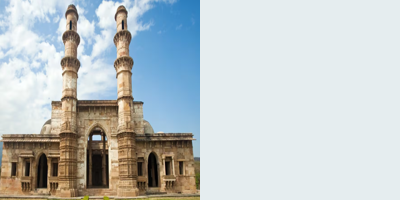

   Left: ORIGINAL image | Right: dominant color picked

🖌️  Painting entire 3D mesh...

📦 Exported → Screenshot_2026-05-07_091803_3d_dominant_color.glb
   Vertices : 39,924
   Faces    : 80,000
   Color    : RGB(229, 237, 239) (from original image) ✅


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


🎉 Done! Preview at: https://gltf-viewer.donmccurdy.com


In [ ]:
# claude-can be ignored
# ================================================
# CELL 9 (CORRECT): Dominant color from ORIGINAL image → whole mesh
# ================================================
import os, gc
import torch
import numpy as np
import trimesh
from PIL import Image
from sklearn.cluster import KMeans
from google.colab import files

# ── Free VRAM ────────────────────────────────────────────────────────────────
print("🧹 Freeing VRAM...")
for var in ['pipeline', 'best_mesh', 'mesh_clean', 'mesh_smooth', 'mesh_dec']:
    try:
        exec(f"del {var}")
    except:
        pass
gc.collect()
torch.cuda.empty_cache()

# ── Find dominant color from ORIGINAL image ───────────────────────────────────
def get_dominant_color(image_path, n_colors=10):
    img = Image.open(image_path).convert("RGB").resize((300, 300), Image.LANCZOS)
    pixels = np.array(img).reshape(-1, 3).astype(np.float32)

    # Remove ONLY pure white (>245) and pure black (<10) — very strict
    not_white = ~np.all(pixels > 245, axis=1)
    not_black = ~np.all(pixels < 10,  axis=1)
    filtered = pixels[not_white & not_black]

    if len(filtered) < n_colors:
        filtered = pixels

    km = KMeans(n_clusters=n_colors, random_state=42, n_init=10)
    km.fit(filtered)

    counts = np.bincount(km.labels_)
    dominant_idx = np.argmax(counts)
    dominant_color = km.cluster_centers_[dominant_idx].astype(np.uint8)

    print("\n   All clusters (most → least dominant):")
    for rank, idx in enumerate(np.argsort(-counts)):
        c = km.cluster_centers_[idx].astype(np.uint8)
        pct = counts[idx] / len(filtered) * 100
        marker = " ← CHOSEN" if idx == dominant_idx else ""
        print(f"   #{rank+1}: RGB({c[0]:3d},{c[1]:3d},{c[2]:3d})  {pct:.1f}%{marker}")

    return tuple(dominant_color)

# ── Show preview ──────────────────────────────────────────────────────────────
def show_preview(color, orig_path):
    from IPython.display import display
    orig  = Image.open(orig_path).convert("RGB").resize((200, 200))
    swatch = Image.new("RGB", (200, 200), color)
    preview = Image.new("RGB", (400, 200))
    preview.paste(orig,   (0,   0))
    preview.paste(swatch, (200, 0))
    display(preview)
    print("   Left: ORIGINAL image | Right: dominant color picked")

# ── Paint mesh ────────────────────────────────────────────────────────────────
def apply_solid_color(mesh, rgb_color):
    n = len(mesh.vertices)
    colors = np.tile(np.array(rgb_color, dtype=np.uint8), (n, 1))
    return trimesh.Trimesh(
        vertices=mesh.vertices,
        faces=mesh.faces,
        vertex_colors=colors,
        process=False
    )

# ── MAIN ─────────────────────────────────────────────────────────────────────

# Use ORIGINAL uploaded image — NOT processed_path (which is whitened)
print(f"\n🔍 Analyzing ORIGINAL image: {img_path}")
dominant_color = get_dominant_color(img_path, n_colors=10)
print(f"\n✅ Dominant color chosen: RGB{dominant_color}")

show_preview(dominant_color, img_path)

print("\n🖌️  Painting entire 3D mesh...")
final_textured_mesh = apply_solid_color(final_mesh, dominant_color)

# ── Export ────────────────────────────────────────────────────────────────────
base_name = os.path.splitext(os.path.basename(img_path))[0].replace(" ", "_")
out_file  = f"{base_name}_3d_dominant_color.glb"
final_textured_mesh.export(out_file)

print(f"\n📦 Exported → {out_file}")
print(f"   Vertices : {len(final_textured_mesh.vertices):,}")
print(f"   Faces    : {len(final_textured_mesh.faces):,}")
print(f"   Color    : RGB{dominant_color} (from original image) ✅")

files.download(out_file)
print("\n🎉 Done! Preview at: https://gltf-viewer.donmccurdy.com")

In [ ]:
# final_deep_seek
# ================================================
# CELL 9: Full vertex colors from original image
# ================================================
import os
import numpy as np
import trimesh
from PIL import Image
from google.colab import files

def project_vertex_colors_robust(mesh, image_path, flip_x=False):
    """
    Map every vertex to a pixel in the image using the full XY bounding box.
    No vertex is left uncolored.
    """
    img = Image.open(image_path).convert("RGB")
    w, h = img.size
    verts = mesh.vertices.copy()

    # XY coordinates
    x = verts[:, 0]
    y = verts[:, 1]

    # Bounding box with 5% margin to avoid edge clipping
    xmin, xmax = x.min(), x.max()
    ymin, ymax = y.min(), y.max()
    dx = xmax - xmin
    dy = ymax - ymin
    margin_x = dx * 0.05
    margin_y = dy * 0.05
    xmin -= margin_x
    xmax += margin_x
    ymin -= margin_y
    ymax += margin_y

    # Normalize to [0,1]
    u = (x - xmin) / (xmax - xmin)
    v = (y - ymin) / (ymax - ymin)
    # Flip Y because image origin is top-left
    v = 1.0 - v

    if flip_x:
        u = 1.0 - u

    # Convert to pixel coordinates
    u_px = np.clip(u * (w - 1), 0, w-1).astype(np.int32)
    v_px = np.clip(v * (h - 1), 0, h-1).astype(np.int32)

    # Sample colors
    img_arr = np.array(img)
    colors = img_arr[v_px, u_px]

    print(f"   Image size: {w}x{h}")
    print(f"   Mesh X range: [{xmin:.3f}, {xmax:.3f}]")
    print(f"   Mesh Y range: [{ymin:.3f}, {ymax:.3f}]")
    print(f"   Flipped X: {flip_x}")

    return trimesh.Trimesh(vertices=verts, faces=mesh.faces,
                           vertex_colors=colors, process=False)

print("🎨 Coloring the entire mesh using original image...\n")

if 'final_mesh' not in globals():
    raise NameError("final_mesh not found. Run Cell 8 first.")

# Generate both normal and flipped versions
print("   Rendering normal mapping...")
normal_mesh = project_vertex_colors_robust(final_mesh, img_path, flip_x=False)
normal_mesh.export("temp_normal.glb")
print("   → Saved: temp_normal.glb\n")

print("   Rendering flipped mapping (left/right swapped)...")
flipped_mesh = project_vertex_colors_robust(final_mesh, img_path, flip_x=True)
flipped_mesh.export("temp_flipped.glb")
print("   → Saved: temp_flipped.glb\n")

# Let user choose which one works
print("📌 Choose the correct mapping:")
print("   - Download both .glb files from the file browser (left sidebar).")
print("   - Open them in a 3D viewer (e.g., https://gltf-viewer.donmccurdy.com).")
print("   - Pick the one where the color covers the ENTIRE mesh (left and right sides).")
print("   - Then change the line below to export that version.\n")

# By default, we export the normal version (you can change this line)
best_mesh = normal_mesh   # <-- change to flipped_mesh if that looks better

base_name = os.path.splitext(os.path.basename(img_path))[0].replace(" ", "_")
out_file = f"{base_name}_3d_full_color.glb"
best_mesh.export(out_file)
print(f"📦 Final export: {out_file}")
print(f"   Vertices: {len(best_mesh.vertices):,}")
print(f"   Faces:    {len(best_mesh.faces):,}")

# Download
files.download(out_file)
print("\n✅ Download started. If it doesn't, find the file in the left sidebar and download manually.")

🎨 Coloring the entire mesh using original image...

   Rendering normal mapping...
   Image size: 525x351
   Mesh X range: [-1.100, 1.095]
   Mesh Y range: [-0.748, 0.738]
   Flipped X: False
   → Saved: temp_normal.glb

   Rendering flipped mapping (left/right swapped)...
   Image size: 525x351
   Mesh X range: [-1.100, 1.095]
   Mesh Y range: [-0.748, 0.738]
   Flipped X: True
   → Saved: temp_flipped.glb

📌 Choose the correct mapping:
   - Download both .glb files from the file browser (left sidebar).
   - Open them in a 3D viewer (e.g., https://gltf-viewer.donmccurdy.com).
   - Pick the one where the color covers the ENTIRE mesh (left and right sides).
   - Then change the line below to export that version.

📦 Final export: Screenshot_2026-05-07_091803_3d_full_color.glb
   Vertices: 39,924
   Faces:    80,000


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ Download started. If it doesn't, find the file in the left sidebar and download manually.


In [ ]:
# ================================================
# CELL 9: Full vertex colors – final working version
# ================================================
import os
import numpy as np
import trimesh
from PIL import Image
from google.colab import files

def apply_image_colors(mesh, image_path, flip_x=False):
    img = Image.open(image_path).convert("RGB")
    w, h = img.size
    verts = mesh.vertices.copy()
    x = verts[:, 0]
    y = verts[:, 1]

    xmin, xmax = x.min(), x.max()
    ymin, ymax = y.min(), y.max()
    dx, dy = xmax - xmin, ymax - ymin
    margin_x, margin_y = dx * 0.2, dy * 0.2
    xmin -= margin_x
    xmax += margin_x
    ymin -= margin_y
    ymax += margin_y

    u = (x - xmin) / (xmax - xmin)
    v = 1.0 - (y - ymin) / (ymax - ymin)
    if flip_x:
        u = 1.0 - u

    u_px = np.clip(u * (w - 1), 0, w-1).astype(np.int32)
    v_px = np.clip(v * (h - 1), 0, h-1).astype(np.int32)

    img_arr = np.array(img)
    colors = img_arr[v_px, u_px]

    return trimesh.Trimesh(vertices=verts, faces=mesh.faces,
                           vertex_colors=colors, process=False)

print("🎨 Creating fully colored meshes...")
normal = apply_image_colors(final_mesh, img_path, flip_x=False)
normal.export("normal_colored.glb")
print("   Saved: normal_colored.glb")

flipped = apply_image_colors(final_mesh, img_path, flip_x=True)
flipped.export("flipped_colored.glb")
print("   Saved: flipped_colored.glb")

print("\n📌 Download both .glb files from the left sidebar.")
print("   Open each in a 3D viewer (e.g., https://gltf-viewer.donmccurdy.com).")
print("   Keep the one where the whole mesh appears colored – that's your final model.")

🎨 Creating fully colored meshes...
   Saved: normal_colored.glb
   Saved: flipped_colored.glb

📌 Download both .glb files from the left sidebar.
   Open each in a 3D viewer (e.g., https://gltf-viewer.donmccurdy.com).
   Keep the one where the whole mesh appears colored – that's your final model.
